# Homework 8.2 - Part II

## Failure Times

We define failure by the absolute-deviation event

$$
|X_t|>R
$$

with

$$
R=2.
$$

The continuous first-passage time is conceptually

$$
\tau
=
\inf
\{
t\ge0:
|X_t|>2
\}.
$$

The numerical simulation detects crossings only on its time grid.

Paths that do not fail before the observation horizon are right-censored.

## Main design

Use

$$
T_{obs}=100
$$

with 5000 realizations.

The main step size is

$$
\Delta t=0.01.
$$

We report:

- failure probability by the horizon;
- survival curve;
- median failure time if reached;
- restricted mean survival time

$$
E[
\min(\tau,T_{obs})
].
$$

We do not interpret the restricted mean as an unrestricted mean failure time.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_2"

config = json.loads(
    (
        DATA_DIR
        / "hw8_2_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

BASE_A = float(
    config["a"]
)

BASE_KAPPA = float(
    config["kappa"]
)

BASE_SIGMA = float(
    config["sigma"]
)

ETA = float(
    config["eta"]
)

X0 = float(
    config["x0"]
)

L0 = float(
    config["l0"]
)

R = 2.0
T_OBS = 100.0
N_PATHS = 5000
MAIN_DT = 0.01
SEED = 63822
BOOTSTRAP_SEED = 63823
BOOTSTRAP_REPS = 1000

In [2]:
def failure_summary(
    failure_times,
    horizon,
):
    failure_times = np.asarray(
        failure_times,
        dtype=float,
    )

    failed = np.isfinite(
        failure_times
    )

    observed_times = np.where(
        failed,
        failure_times,
        horizon,
    )

    failure_probability = float(
        np.mean(
            failed
        )
    )

    median_failure = np.nan

    if (
        failure_probability
        >= 0.5
    ):
        finite_sorted = np.sort(
            failure_times[
                failed
            ]
        )

        cumulative = (
            np.arange(
                1,
                len(
                    finite_sorted
                )
                + 1
            )
            / len(
                failure_times
            )
        )

        index = np.argmax(
            cumulative
            >= 0.5
        )

        median_failure = float(
            finite_sorted[
                index
            ]
        )

    return {
        "failure_probability": (
            failure_probability
        ),
        "restricted_mean_survival": float(
            np.mean(
                observed_times
            )
        ),
        "median_failure_time_if_reached": (
            median_failure
        ),
        "censored_fraction": float(
            1.0
            - failure_probability
        ),
    }


def bootstrap_intervals(
    failure_times,
    horizon,
    seed,
    reps,
):
    failure_times = np.asarray(
        failure_times,
        dtype=float,
    )

    failed = np.isfinite(
        failure_times
    )

    observed = np.where(
        failed,
        failure_times,
        horizon,
    )

    rng = np.random.default_rng(
        seed
    )

    failure_values = np.empty(
        reps,
        dtype=float,
    )

    rmst_values = np.empty(
        reps,
        dtype=float,
    )

    n = len(
        failure_times
    )

    for b in range(
        reps
    ):
        index = rng.integers(
            0,
            n,
            size=n,
        )

        failure_values[
            b
        ] = np.mean(
            failed[
                index
            ]
        )

        rmst_values[
            b
        ] = np.mean(
            observed[
                index
            ]
        )

    return {
        "failure_probability_ci_low": float(
            np.quantile(
                failure_values,
                0.025,
            )
        ),
        "failure_probability_ci_high": float(
            np.quantile(
                failure_values,
                0.975,
            )
        ),
        "rmst_ci_low": float(
            np.quantile(
                rmst_values,
                0.025,
            )
        ),
        "rmst_ci_high": float(
            np.quantile(
                rmst_values,
                0.975,
            )
        ),
    }

In [3]:
def simulate_failure_times(
    a,
    kappa,
    sigma,
    dt,
    horizon,
    n_paths,
    seed,
):
    n_steps = int(
        round(
            horizon / dt
        )
    )

    rng = np.random.default_rng(
        seed
    )

    x = np.full(
        n_paths,
        X0,
        dtype=float,
    )

    l = np.full(
        n_paths,
        L0,
        dtype=float,
    )

    failure_times = np.full(
        n_paths,
        np.nan,
        dtype=float,
    )

    alive = np.ones(
        n_paths,
        dtype=bool,
    )

    for step in range(
        1,
        n_steps + 1,
    ):
        z = rng.normal(
            size=n_paths
        )

        x_old = x.copy()
        l_old = l.copy()

        x = (
            x_old
            + a
            * (
                -x_old
                + l_old
            )
            * dt
            + sigma
            * np.sqrt(
                dt
            )
            * z
        )

        l = (
            l_old
            - kappa
            * np.abs(
                x_old
            )
            / (
                1.0
                + ETA
                * np.abs(
                    l_old
                )
            )
            * dt
        )

        newly_failed = (
            alive
            & (
                np.abs(
                    x
                )
                > R
            )
        )

        failure_times[
            newly_failed
        ] = (
            step * dt
        )

        alive[
            newly_failed
        ] = False

    return failure_times


main_failure_times = (
    simulate_failure_times(
        a=BASE_A,
        kappa=BASE_KAPPA,
        sigma=BASE_SIGMA,
        dt=MAIN_DT,
        horizon=T_OBS,
        n_paths=N_PATHS,
        seed=SEED,
    )
)

main_summary = failure_summary(
    main_failure_times,
    T_OBS,
)

main_summary.update(
    bootstrap_intervals(
        main_failure_times,
        T_OBS,
        BOOTSTRAP_SEED,
        BOOTSTRAP_REPS,
    )
)

main_summary[
    "grid_crossing_detection_only"
] = True

main_summary[
    "dt"
] = MAIN_DT

main_summary[
    "horizon"
] = T_OBS

main_summary[
    "n_paths"
] = N_PATHS

(
    DATA_DIR
    / "part2_main_failure_summary.json"
).write_text(
    json.dumps(
        main_summary,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        main_summary,
        indent=2,
    )
)

{
  "failure_probability": 0.5808,
  "restricted_mean_survival": 95.313226,
  "median_failure_time_if_reached": 98.09,
  "censored_fraction": 0.4192,
  "failure_probability_ci_low": 0.5669949999999999,
  "failure_probability_ci_high": 0.5938,
  "rmst_ci_low": 95.15548869999999,
  "rmst_ci_high": 95.47817524999999,
  "grid_crossing_detection_only": true,
  "dt": 0.01,
  "horizon": 100.0,
  "n_paths": 5000
}


## Survival curve

Because every nonfailed path is censored at the same horizon, the empirical survival curve is

$$
\widehat S(t)
=
1-
\frac{
\#\{\widehat\tau_i\le t\}
}{
N
}.
$$

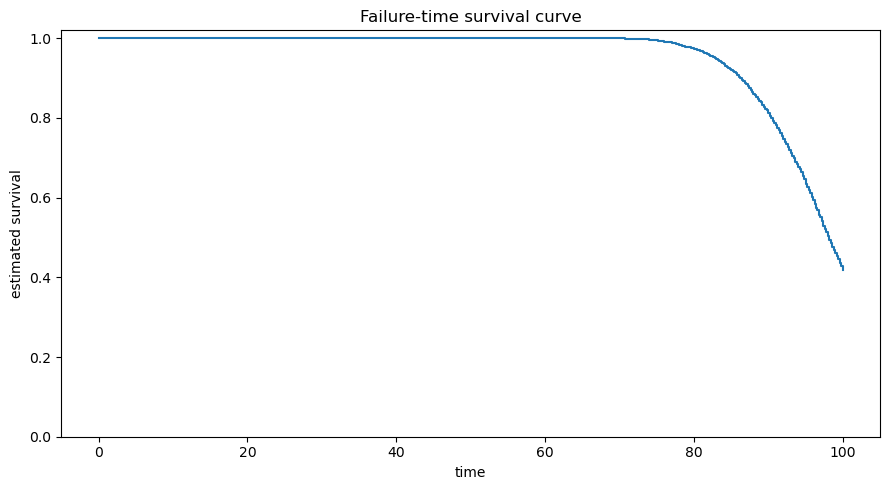

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\result images\hw8_2\part2_survival_curve.png


In [4]:
survival_times = np.linspace(
    0.0,
    T_OBS,
    501,
)

survival_values = []

for t in survival_times:
    survival_values.append(
        1.0
        - np.mean(
            np.isfinite(
                main_failure_times
            )
            & (
                main_failure_times
                <= t
            )
        )
    )


survival_table = pd.DataFrame({
    "t": survival_times,
    "survival_probability": (
        survival_values
    ),
})

survival_table.to_csv(
    DATA_DIR
    / "part2_survival_curve.csv",
    index=False,
)

plt.figure(
    figsize=(9, 5)
)

plt.step(
    survival_table["t"],
    survival_table[
        "survival_probability"
    ],
    where="post",
)

plt.xlabel("time")
plt.ylabel("estimated survival")
plt.title(
    "Failure-time survival curve"
)
plt.ylim(
    0.0,
    1.02,
)
plt.tight_layout()

path = (
    RESULT_DIR
    / "part2_survival_curve.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    path.resolve(),
)

## Step-size sensitivity with common Brownian increments

We compare

$$
\Delta t
=
0.02,\ 0.01,\ 0.005.
$$

Brownian increments are generated on the finest grid and summed to form the increments used by the coarser methods.

Thus the three discretizations are driven by the same underlying Brownian paths.

In [5]:
DT_FINE = 0.005

step_sizes = [
    0.005,
    0.01,
    0.02,
]

ratios = {
    dt: int(
        round(
            dt / DT_FINE
        )
    )
    for dt
    in step_sizes
}

fine_steps = int(
    round(
        T_OBS
        / DT_FINE
    )
)

rng = np.random.default_rng(
    63824
)

states = {}

for dt in step_sizes:
    states[
        dt
    ] = {
        "x": np.full(
            N_PATHS,
            X0,
            dtype=float,
        ),
        "l": np.full(
            N_PATHS,
            L0,
            dtype=float,
        ),
        "alive": np.ones(
            N_PATHS,
            dtype=bool,
        ),
        "failure_times": np.full(
            N_PATHS,
            np.nan,
            dtype=float,
        ),
        "accumulated_dW": np.zeros(
            N_PATHS,
            dtype=float,
        ),
        "fine_count": 0,
        "coarse_step": 0,
    }


for fine_step in range(
    1,
    fine_steps + 1,
):
    dW_fine = (
        np.sqrt(
            DT_FINE
        )
        * rng.normal(
            size=N_PATHS
        )
    )

    for dt in step_sizes:
        state = states[
            dt
        ]

        state[
            "accumulated_dW"
        ] += dW_fine

        state[
            "fine_count"
        ] += 1

        if (
            state[
                "fine_count"
            ]
            == ratios[
                dt
            ]
        ):
            x_old = state[
                "x"
            ].copy()

            l_old = state[
                "l"
            ].copy()

            state[
                "x"
            ] = (
                x_old
                + BASE_A
                * (
                    -x_old
                    + l_old
                )
                * dt
                + BASE_SIGMA
                * state[
                    "accumulated_dW"
                ]
            )

            state[
                "l"
            ] = (
                l_old
                - BASE_KAPPA
                * np.abs(
                    x_old
                )
                / (
                    1.0
                    + ETA
                    * np.abs(
                        l_old
                    )
                )
                * dt
            )

            state[
                "coarse_step"
            ] += 1

            newly_failed = (
                state[
                    "alive"
                ]
                & (
                    np.abs(
                        state[
                            "x"
                        ]
                    )
                    > R
                )
            )

            state[
                "failure_times"
            ][
                newly_failed
            ] = (
                state[
                    "coarse_step"
                ]
                * dt
            )

            state[
                "alive"
            ][
                newly_failed
            ] = False

            state[
                "accumulated_dW"
            ].fill(
                0.0
            )

            state[
                "fine_count"
            ] = 0


step_rows = []

for dt in step_sizes:
    summary = failure_summary(
        states[
            dt
        ][
            "failure_times"
        ],
        T_OBS,
    )

    step_rows.append({
        "dt": dt,
        **summary,
    })


step_table = pd.DataFrame(
    step_rows
)

step_table.to_csv(
    DATA_DIR
    / "part2_step_size_sensitivity.csv",
    index=False,
)

print(
    step_table.to_string(
        index=False
    )
)

   dt  failure_probability  restricted_mean_survival  median_failure_time_if_reached  censored_fraction
0.005               0.6006                 95.121554                          97.575             0.3994
0.010               0.5962                 95.159834                          97.630             0.4038
0.020               0.5886                 95.252728                          97.840             0.4114


## Parameter sensitivity with common Brownian increments

Each parameter is varied by 25 percent while the failure definition and all other settings remain fixed.

The tested values are

$$
\sigma
=
0.15,\ 0.20,\ 0.25,
$$

$$
a
=
0.375,\ 0.50,\ 0.625,
$$

and

$$
\kappa
=
0.0375,\ 0.0500,\ 0.0625.
$$

All scenarios use the same Brownian increments path by path.

In [6]:
scenario_specs = [
    {
        "name": "baseline",
        "a": BASE_A,
        "kappa": BASE_KAPPA,
        "sigma": BASE_SIGMA,
    },
    {
        "name": "sigma_low",
        "a": BASE_A,
        "kappa": BASE_KAPPA,
        "sigma": 0.75 * BASE_SIGMA,
    },
    {
        "name": "sigma_high",
        "a": BASE_A,
        "kappa": BASE_KAPPA,
        "sigma": 1.25 * BASE_SIGMA,
    },
    {
        "name": "a_low",
        "a": 0.75 * BASE_A,
        "kappa": BASE_KAPPA,
        "sigma": BASE_SIGMA,
    },
    {
        "name": "a_high",
        "a": 1.25 * BASE_A,
        "kappa": BASE_KAPPA,
        "sigma": BASE_SIGMA,
    },
    {
        "name": "kappa_low",
        "a": BASE_A,
        "kappa": 0.75 * BASE_KAPPA,
        "sigma": BASE_SIGMA,
    },
    {
        "name": "kappa_high",
        "a": BASE_A,
        "kappa": 1.25 * BASE_KAPPA,
        "sigma": BASE_SIGMA,
    },
]

n_steps = int(
    round(
        T_OBS
        / MAIN_DT
    )
)

rng = np.random.default_rng(
    63825
)

scenario_states = {}

for spec in scenario_specs:
    scenario_states[
        spec["name"]
    ] = {
        "x": np.full(
            N_PATHS,
            X0,
            dtype=float,
        ),
        "l": np.full(
            N_PATHS,
            L0,
            dtype=float,
        ),
        "alive": np.ones(
            N_PATHS,
            dtype=bool,
        ),
        "failure_times": np.full(
            N_PATHS,
            np.nan,
            dtype=float,
        ),
    }


for step in range(
    1,
    n_steps + 1,
):
    z = rng.normal(
        size=N_PATHS
    )

    for spec in scenario_specs:
        state = scenario_states[
            spec["name"]
        ]

        x_old = state[
            "x"
        ].copy()

        l_old = state[
            "l"
        ].copy()

        state[
            "x"
        ] = (
            x_old
            + spec[
                "a"
            ]
            * (
                -x_old
                + l_old
            )
            * MAIN_DT
            + spec[
                "sigma"
            ]
            * np.sqrt(
                MAIN_DT
            )
            * z
        )

        state[
            "l"
        ] = (
            l_old
            - spec[
                "kappa"
            ]
            * np.abs(
                x_old
            )
            / (
                1.0
                + ETA
                * np.abs(
                    l_old
                )
            )
            * MAIN_DT
        )

        newly_failed = (
            state[
                "alive"
            ]
            & (
                np.abs(
                    state[
                        "x"
                    ]
                )
                > R
            )
        )

        state[
            "failure_times"
        ][
            newly_failed
        ] = (
            step * MAIN_DT
        )

        state[
            "alive"
        ][
            newly_failed
        ] = False

In [7]:
baseline_times = (
    scenario_states[
        "baseline"
    ][
        "failure_times"
    ]
)

baseline_observed = np.where(
    np.isfinite(
        baseline_times
    ),
    baseline_times,
    T_OBS,
)

rng_boot = np.random.default_rng(
    63826
)

scenario_rows = []

for spec in scenario_specs:
    times = (
        scenario_states[
            spec["name"]
        ][
            "failure_times"
        ]
    )

    summary = failure_summary(
        times,
        T_OBS,
    )

    observed = np.where(
        np.isfinite(
            times
        ),
        times,
        T_OBS,
    )

    paired_difference = (
        observed
        - baseline_observed
    )

    bootstrap_means = np.empty(
        BOOTSTRAP_REPS,
        dtype=float,
    )

    for b in range(
        BOOTSTRAP_REPS
    ):
        index = rng_boot.integers(
            0,
            N_PATHS,
            size=N_PATHS,
        )

        bootstrap_means[
            b
        ] = np.mean(
            paired_difference[
                index
            ]
        )

    scenario_rows.append({
        "scenario": (
            spec[
                "name"
            ]
        ),
        "a": spec[
            "a"
        ],
        "kappa": spec[
            "kappa"
        ],
        "sigma": spec[
            "sigma"
        ],
        **summary,
        "paired_rmst_difference_vs_baseline": float(
            np.mean(
                paired_difference
            )
        ),
        "paired_difference_ci_low": float(
            np.quantile(
                bootstrap_means,
                0.025,
            )
        ),
        "paired_difference_ci_high": float(
            np.quantile(
                bootstrap_means,
                0.975,
            )
        ),
    })


scenario_table = pd.DataFrame(
    scenario_rows
)

scenario_table.to_csv(
    DATA_DIR
    / "part2_parameter_sensitivity.csv",
    index=False,
)

nonbaseline = scenario_table[
    scenario_table[
        "scenario"
    ] != "baseline"
].copy()

best_index = nonbaseline[
    "paired_rmst_difference_vs_baseline"
].idxmax()

best_local = nonbaseline.loc[
    best_index
]

print(
    scenario_table.to_string(
        index=False
    )
)

print()
print(
    "Largest local RMST increase:",
    best_local[
        "scenario"
    ],
)

print(
    "Paired difference:",
    best_local[
        "paired_rmst_difference_vs_baseline"
    ],
)

  scenario     a  kappa  sigma  failure_probability  restricted_mean_survival  median_failure_time_if_reached  censored_fraction  paired_rmst_difference_vs_baseline  paired_difference_ci_low  paired_difference_ci_high
  baseline 0.500 0.0500   0.20               0.5904                 95.323088                           97.85             0.4096                            0.000000                  0.000000                   0.000000
 sigma_low 0.500 0.0500   0.15               0.2798                 98.680004                             NaN             0.7202                            3.356916                  3.226118                   3.476374
sigma_high 0.500 0.0500   0.25               0.8010                 90.258324                           91.36             0.1990                           -5.064764                 -5.236683                  -4.905039
     a_low 0.375 0.0500   0.20               0.6566                 93.360610                           95.39             0.3434

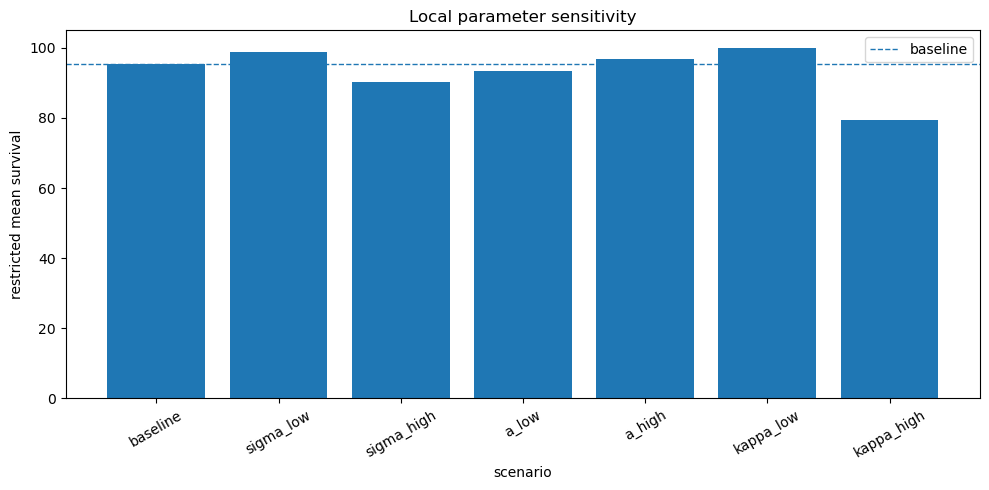

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\result images\hw8_2\part2_parameter_sensitivity.png


In [8]:
plot_table = scenario_table.copy()

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    plot_table[
        "scenario"
    ],
    plot_table[
        "restricted_mean_survival"
    ],
)

plt.axhline(
    scenario_table.loc[
        scenario_table[
            "scenario"
        ] == "baseline",
        "restricted_mean_survival",
    ].iloc[0],
    linestyle="--",
    linewidth=1.0,
    label="baseline",
)

plt.ylabel(
    "restricted mean survival"
)
plt.xlabel(
    "scenario"
)
plt.title(
    "Local parameter sensitivity"
)
plt.xticks(
    rotation=30
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "part2_parameter_sensitivity.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    path.resolve(),
)

# Part II Interpretation

The parameter ranking produced here is local to the chosen baseline, failure threshold, horizon, and relative perturbation size.

It should not be described as a universal ranking of $\sigma$, $a$, and $\kappa$.

The main failure-time results also remain finite-horizon statements because paths surviving to $T_{obs}$ are right-censored.